# Notebook de documentacion, tratamiento datos y entrenamiento


## Equipo
- Alumno 1 : Damián Grimaldi
- Alumno 2 : Nicolas Duclos

# **Descripción del dataset**

El dataset utilizado, es de proveniente de kaggle, que contiene imagenes de `105` famosos distintos, y con un total de `17534` fotos distribuidas. Cuyo formato de las imagenes son de `.jpg`

# **Objetivo de la sección**

Cuyo objetivo es preparar al dataset en condiciones para realizar un entrenamiento para reconocer rostros.

# **Librerias**

In [1]:
import kagglehub
import os

from sklearn.metrics.pairwise import cosine_similarity

import cv2
import numpy as np
import matplotlib.pyplot as plt

from itertools import combinations

c:\Users\grima\Desktop\UNR\TUIA\5° cuatri\COMPUTER VISION\PRACTICA\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Download latest version
path = kagglehub.dataset_download(
    "hereisburak/pins-face-recognition",
)

print("Path to dataset files:", path)

Path to dataset files: C:\Users\grima\.cache\kagglehub\datasets\hereisburak\pins-face-recognition\versions\1


Descargamos el dataset de kaggle

# EDA

In [41]:
def grafico_barra(x, y, titulo, xlabel, y_label, yticks = 25):

    plt.figure(figsize=(30, 10))

    plt.bar(x, y, width=0.5)

    plt.title(titulo)
    plt.xlabel(xlabel)
    plt.ylabel(y_label)

    plt.xticks(rotation=45, ha="right")

    plt.yticks(range(0, max(y) + yticks, yticks))

    plt.show()

## **Balanceo del dataset**

In [3]:
dataset_dir = os.path.join(path, "105_classes_pins_dataset")

extensiones = {".jpg", ".jpeg", ".png", ".bmp", ".gif", ".webp"}
total_imagenes = 0

persona_cantidad = {}
persona_imagenes = {}

for carpeta, _, archivos in os.walk(dataset_dir):
    imagenes = [
        archivo for archivo in archivos
        if os.path.splitext(archivo)[1].lower() in extensiones
    ]

    
    if imagenes:
        persona_imagenes[os.path.basename(carpeta)] = imagenes
        persona_cantidad[os.path.basename(carpeta)] = len(imagenes)
        print(f"{os.path.basename(carpeta)}: {len(imagenes)} imágenes")
        total_imagenes += len(imagenes)

print(f"\nTotal de imágenes: {total_imagenes}")

pins_Adriana Lima: 213 imágenes
pins_Alex Lawther: 152 imágenes
pins_Alexandra Daddario: 225 imágenes
pins_Alvaro Morte: 139 imágenes
pins_alycia dabnem carey: 211 imágenes
pins_Amanda Crew: 117 imágenes
pins_amber heard: 218 imágenes
pins_Andy Samberg: 196 imágenes
pins_Anne Hathaway: 203 imágenes
pins_Anthony Mackie: 124 imágenes
pins_Avril Lavigne: 162 imágenes
pins_barack obama: 119 imágenes
pins_barbara palvin: 197 imágenes
pins_Ben Affleck: 126 imágenes
pins_Bill Gates: 122 imágenes
pins_Bobby Morley: 138 imágenes
pins_Brenton Thwaites: 209 imágenes
pins_Brian J. Smith: 102 imágenes
pins_Brie Larson: 169 imágenes
pins_camila mendes: 162 imágenes
pins_Chris Evans: 166 imágenes
pins_Chris Hemsworth: 159 imágenes
pins_Chris Pratt: 176 imágenes
pins_Christian Bale: 154 imágenes
pins_Cristiano Ronaldo: 98 imágenes
pins_Danielle Panabaker: 181 imágenes
pins_Dominic Purcell: 146 imágenes
pins_Dwayne Johnson: 141 imágenes
pins_Eliza Taylor: 162 imágenes
pins_Elizabeth Lail: 158 imágenes


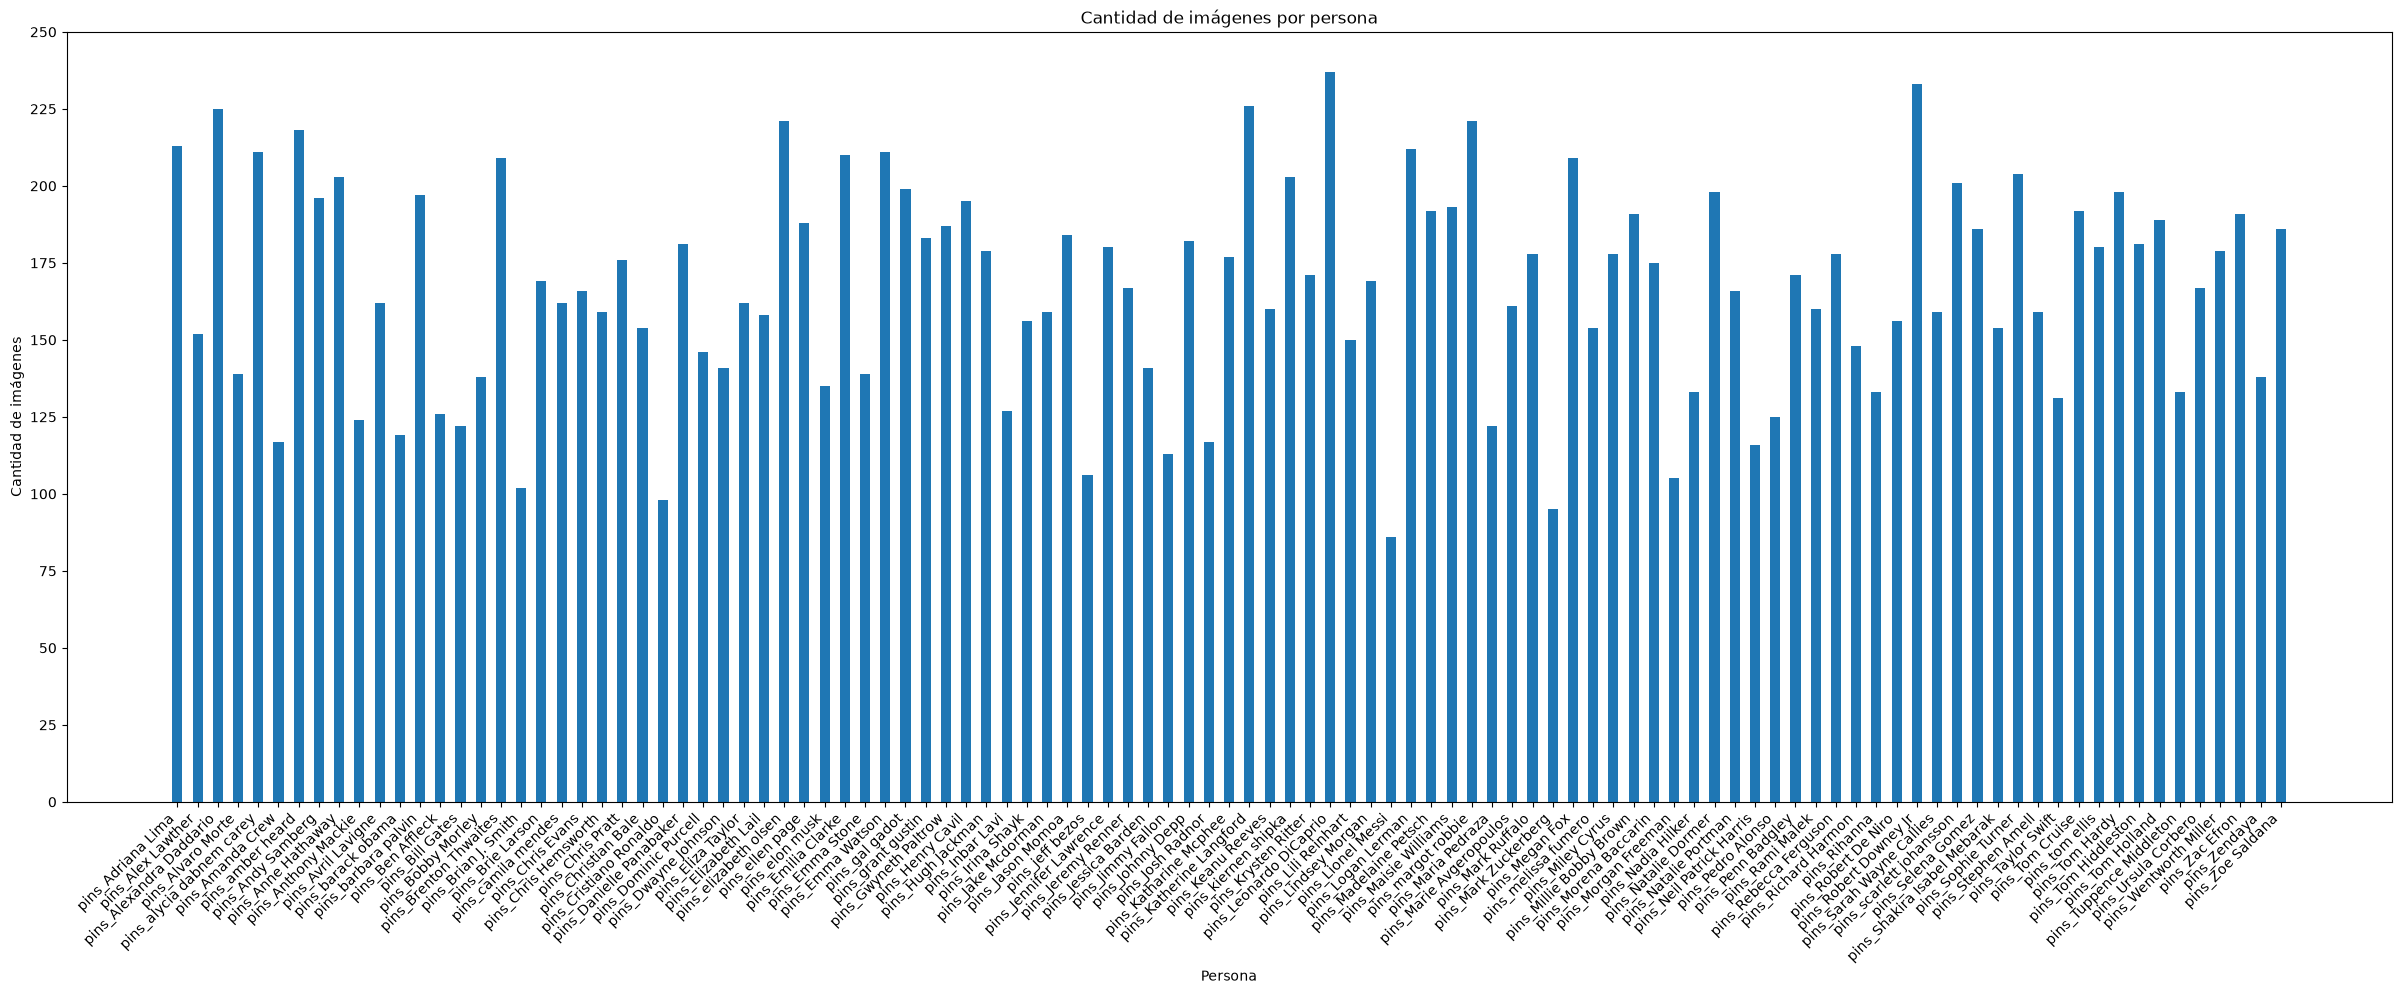

In [37]:
grafico_barra(
    list(persona_cantidad.keys()),
    list(persona_cantidad.values()),
    "Cantidad de imágenes por persona",
    "Persona",
    "Cantidad de imágenes"
)

Se puede obsevar que el dataset esta desbalanceado, ya que en el, ronda entre 86 imagenes pertenecientes a Lionel Messi, y 237 imagenes pertenecientes a Leonardo DiCaprio. Antes de realizar alguna tecnica de data augmentation, hay que verificar, dichas imagenes, cumplen cierto formato, y a su vez, verificar si todas son optimas a utilizar, por lo que primero se va a realizar una limpieza de las imagenes.

In [5]:
persona_cantidad_sorted = dict(sorted(persona_cantidad.items(), key=lambda item: item[1], reverse=True))
persona_cantidad_sorted

{'pins_Leonardo DiCaprio': 237,
 'pins_Robert Downey Jr': 233,
 'pins_Katherine Langford': 226,
 'pins_Alexandra Daddario': 225,
 'pins_elizabeth olsen': 221,
 'pins_margot robbie': 221,
 'pins_amber heard': 218,
 'pins_Adriana Lima': 213,
 'pins_Logan Lerman': 212,
 'pins_alycia dabnem carey': 211,
 'pins_Emma Watson': 211,
 'pins_Emilia Clarke': 210,
 'pins_Brenton Thwaites': 209,
 'pins_Megan Fox': 209,
 'pins_Sophie Turner': 204,
 'pins_Anne Hathaway': 203,
 'pins_kiernen shipka': 203,
 'pins_scarlett johansson': 201,
 'pins_gal gadot': 199,
 'pins_Natalie Dormer': 198,
 'pins_Tom Hardy': 198,
 'pins_barbara palvin': 197,
 'pins_Andy Samberg': 196,
 'pins_Henry Cavil': 195,
 'pins_Maisie Williams': 193,
 'pins_Madelaine Petsch': 192,
 'pins_Tom Cruise': 192,
 'pins_Millie Bobby Brown': 191,
 'pins_Zac Efron': 191,
 'pins_Tom Holland': 189,
 'pins_ellen page': 188,
 'pins_Gwyneth Paltrow': 187,
 'pins_Selena Gomez': 186,
 'pins_Zoe Saldana': 186,
 'pins_Jason Momoa': 184,
 'pins_gra

## **Limpieza de imagenes**

### **Validación de tamaño minimo**

In [6]:
# tamaño minimo 112x112

personas_que_no_cumplen = {}
personas_cumplen_ruta = {}

for persona, imagenes in persona_imagenes.items():
    for imagen in imagenes:
        ruta_imagen = os.path.join(dataset_dir, persona, imagen)
        img = cv2.imread(ruta_imagen)
        if img is None:
            print(f"No se pudo leer la imagen: {ruta_imagen}")
            continue

        alto, ancho, canales = img.shape

        if ancho < 112 or alto < 112:
            if persona not in personas_que_no_cumplen:
                personas_que_no_cumplen[persona] = []
            personas_que_no_cumplen[persona].append(imagen)

        else:
            if persona not in personas_cumplen_ruta:
                personas_cumplen_ruta[persona] = []
            personas_cumplen_ruta[persona].append(imagen)

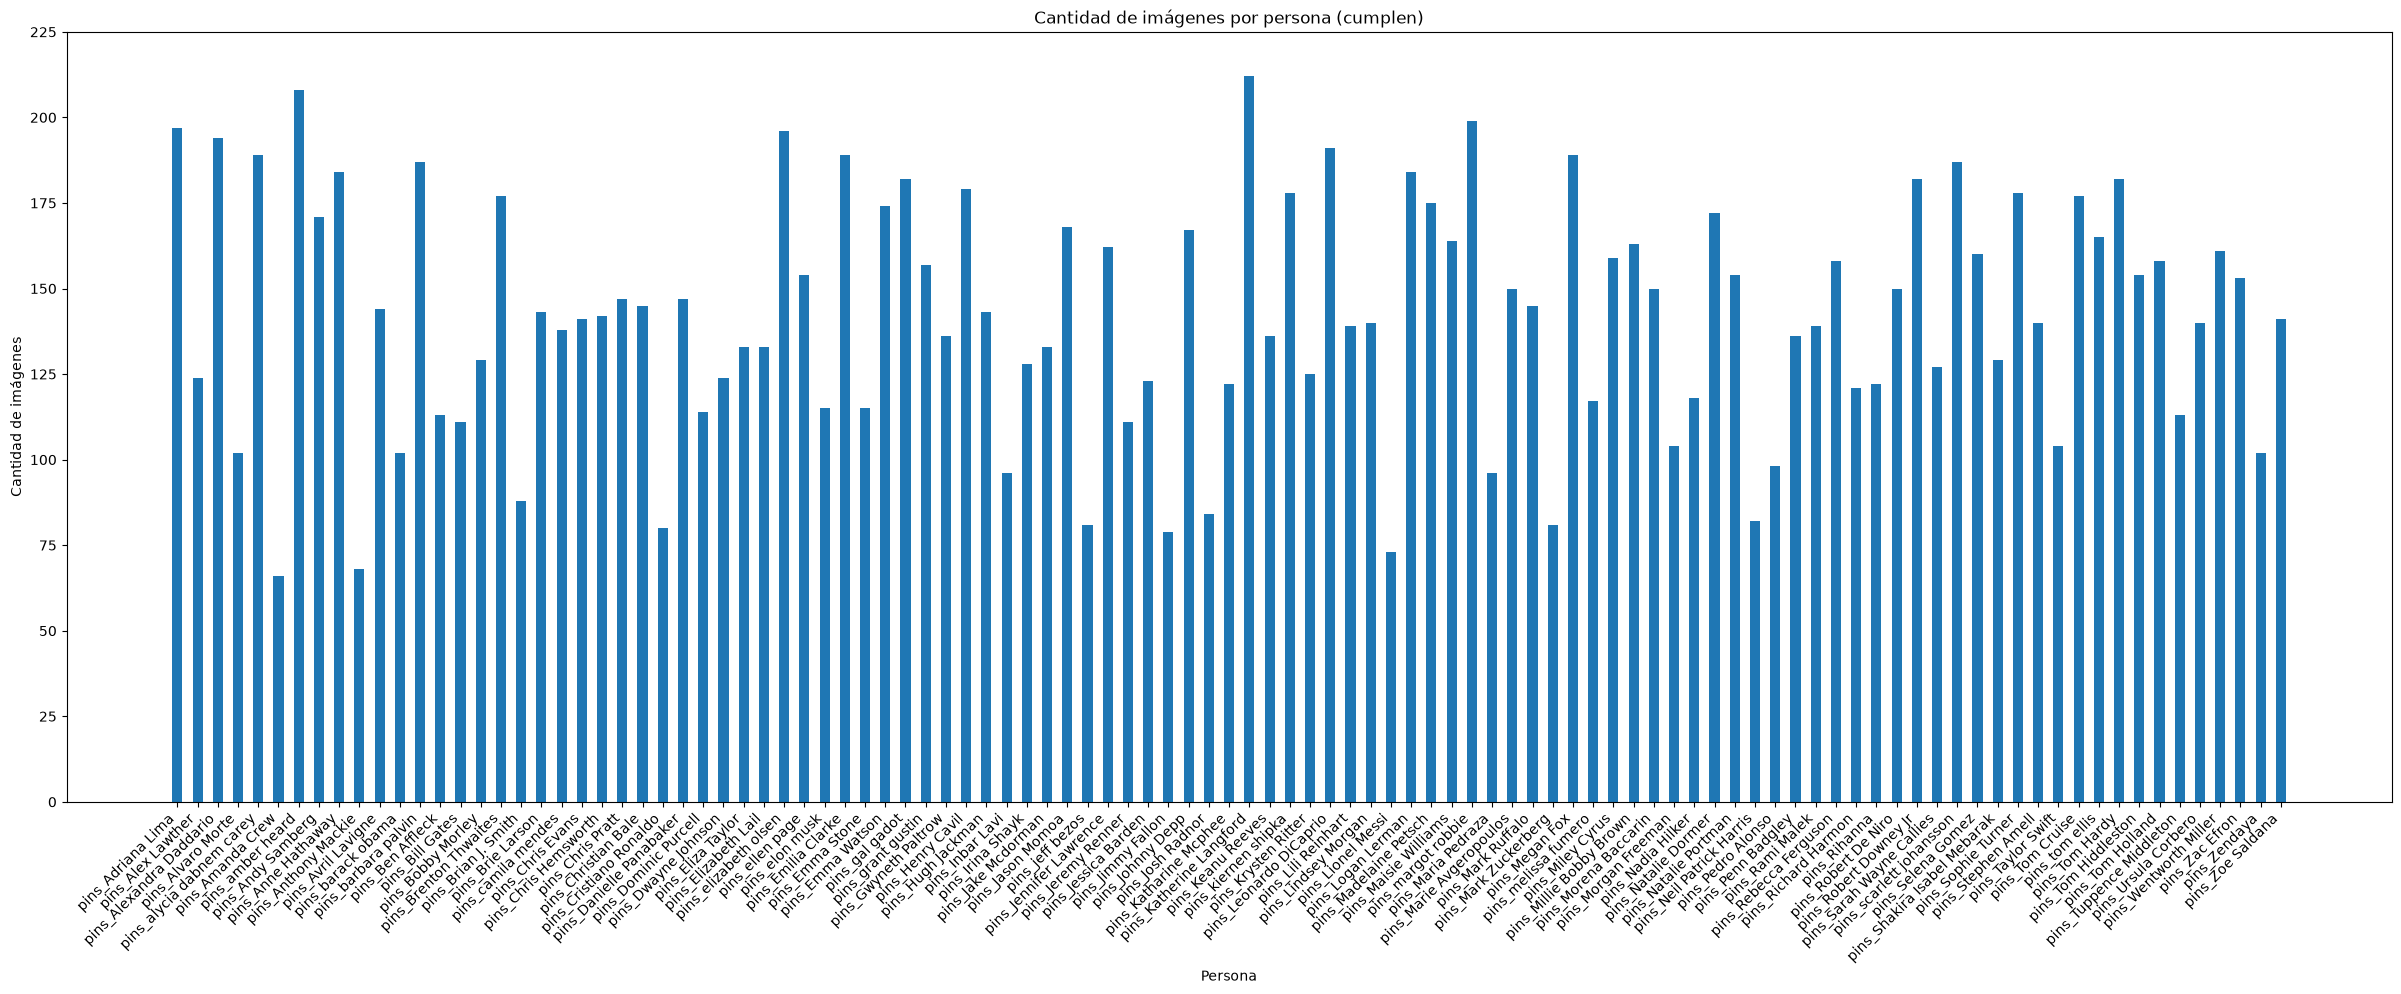

In [38]:
personas_no_cumplen = {persona: len(imagenes) for persona, imagenes in personas_que_no_cumplen.items()}
personas_cumplen = {persona: persona_cantidad[persona] - len(imagenes) for persona, imagenes in personas_que_no_cumplen.items()}

grafico_barra(
    list(personas_cumplen.keys()),
    list(personas_cumplen.values()),
    "Cantidad de imágenes por persona (cumplen)",
    "Persona",
    "Cantidad de imágenes"
)

In [39]:
maximo = personas_no_cumplen[max(personas_no_cumplen, key=personas_no_cumplen.get)]
minimo = personas_no_cumplen[min(personas_no_cumplen, key=personas_no_cumplen.get)]

print("Maximas personas que no cumplen con el tamaño mínimo de 112x112:", maximo)
print("Minimo de imágenes que no cumplen con el tamaño mínimo de 112x112:", minimo)

minimo_cumplen = personas_cumplen[min(personas_cumplen, key=personas_cumplen.get)]
maximo_cumplen = personas_cumplen[max(personas_cumplen, key=personas_cumplen.get)]
print("Minimo de imágenes que cumplen con el tamaño mínimo de 112x112:", minimo_cumplen)
print("Maximo de imágenes que cumplen con el tamaño mínimo de 112x112:", maximo_cumplen)

Maximas personas que no cumplen con el tamaño mínimo de 112x112: 56
Minimo de imágenes que no cumplen con el tamaño mínimo de 112x112: 1
Minimo de imágenes que cumplen con el tamaño mínimo de 112x112: 66
Maximo de imágenes que cumplen con el tamaño mínimo de 112x112: 212


Luego de verificar y eliminar las fotos que no cumplen con el formato minimo, se eliminaron, pasando un nuevo rango, de 66 a 212 imagenes, aun asi, esto sigue siendo desbalanceado.

In [8]:
personas_cumplen_sorted = dict(sorted(personas_cumplen.items(), key=lambda item: item[1], reverse=True))
personas_cumplen_sorted

{'pins_Katherine Langford': 212,
 'pins_amber heard': 208,
 'pins_margot robbie': 199,
 'pins_Adriana Lima': 197,
 'pins_elizabeth olsen': 196,
 'pins_Alexandra Daddario': 194,
 'pins_Leonardo DiCaprio': 191,
 'pins_alycia dabnem carey': 189,
 'pins_Emilia Clarke': 189,
 'pins_Megan Fox': 189,
 'pins_barbara palvin': 187,
 'pins_scarlett johansson': 187,
 'pins_Anne Hathaway': 184,
 'pins_Logan Lerman': 184,
 'pins_gal gadot': 182,
 'pins_Robert Downey Jr': 182,
 'pins_Tom Hardy': 182,
 'pins_Henry Cavil': 179,
 'pins_kiernen shipka': 178,
 'pins_Sophie Turner': 178,
 'pins_Brenton Thwaites': 177,
 'pins_Tom Cruise': 177,
 'pins_Madelaine Petsch': 175,
 'pins_Emma Watson': 174,
 'pins_Natalie Dormer': 172,
 'pins_Andy Samberg': 171,
 'pins_Jason Momoa': 168,
 'pins_Johnny Depp': 167,
 'pins_tom ellis': 165,
 'pins_Maisie Williams': 164,
 'pins_Millie Bobby Brown': 163,
 'pins_Jennifer Lawrence': 162,
 'pins_Wentworth Miller': 161,
 'pins_Selena Gomez': 160,
 'pins_Miley Cyrus': 159,
 '

### **Nitidez**

In [9]:
resultados = {}

for persona, imagenes in personas_cumplen_ruta.items():

    for i in range(len(imagenes)):
        gris = cv2.cvtColor(cv2.imread(os.path.join(dataset_dir, persona, imagenes[i])), cv2.COLOR_BGR2GRAY)

        nitidez = cv2.Laplacian(gris, cv2.CV_64F).var()

        if persona not in resultados:
            resultados[persona] = []

        resultados[persona].append({
            "imagen": str(os.path.join(dataset_dir, persona, imagenes[i])),
            "nitidez": nitidez
        })

In [10]:
adriana = resultados["pins_Adriana Lima"]

print("Resultados de nitidez para Adriana Lima:")

adriana_sorted = sorted(adriana, key=lambda x: x['nitidez'])

for dato in adriana_sorted:
    print(f"Imagen: {dato['imagen']}, Nitidez: {dato['nitidez']}")

Resultados de nitidez para Adriana Lima:
Imagen: C:\Users\grima\.cache\kagglehub\datasets\hereisburak\pins-face-recognition\versions\1\105_classes_pins_dataset\pins_Adriana Lima\Adriana Lima240_140.jpg, Nitidez: 15.007787563509044
Imagen: C:\Users\grima\.cache\kagglehub\datasets\hereisburak\pins-face-recognition\versions\1\105_classes_pins_dataset\pins_Adriana Lima\Adriana Lima172_73.jpg, Nitidez: 29.487041994660668
Imagen: C:\Users\grima\.cache\kagglehub\datasets\hereisburak\pins-face-recognition\versions\1\105_classes_pins_dataset\pins_Adriana Lima\Adriana Lima10_2.jpg, Nitidez: 40.54799407772943
Imagen: C:\Users\grima\.cache\kagglehub\datasets\hereisburak\pins-face-recognition\versions\1\105_classes_pins_dataset\pins_Adriana Lima\Adriana Lima126_28.jpg, Nitidez: 41.87881692427955
Imagen: C:\Users\grima\.cache\kagglehub\datasets\hereisburak\pins-face-recognition\versions\1\105_classes_pins_dataset\pins_Adriana Lima\Adriana Lima232_133.jpg, Nitidez: 46.94831378280484
Imagen: C:\Users\

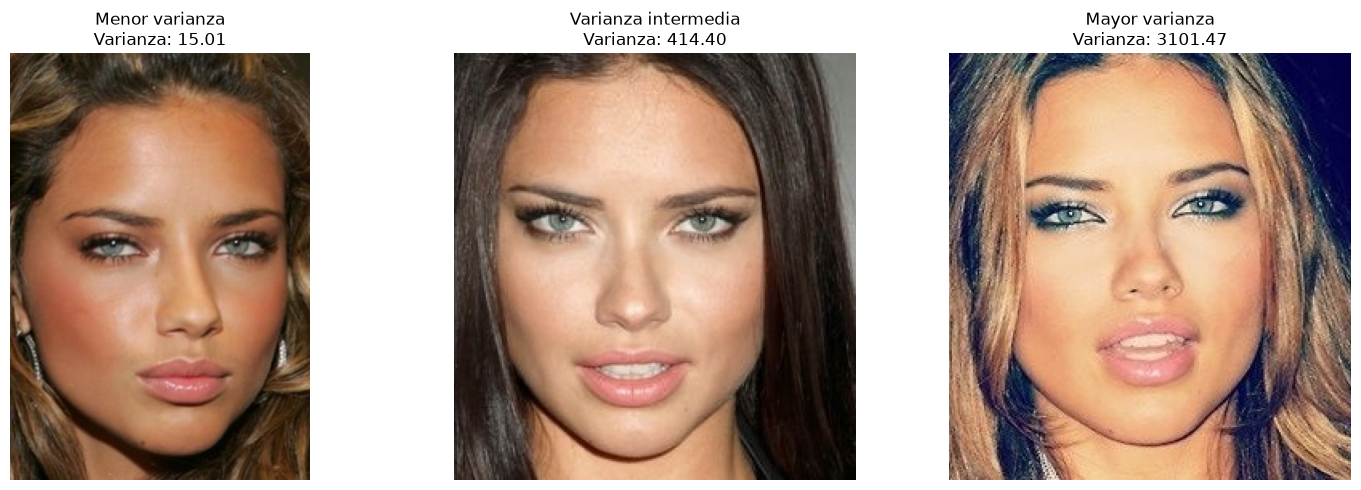

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

indices = [
    0,
    len(adriana_sorted) // 2,
    -1
]

titulos = [
    "Menor varianza",
    "Varianza intermedia",
    "Mayor varianza"
]

for ax, indice, titulo in zip(axes, indices, titulos):
    imagen = cv2.imread(adriana_sorted[indice]["imagen"])
    imagen = cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB)

    ax.imshow(imagen)
    ax.set_title(
        f"{titulo}\nVarianza: {adriana_sorted[indice]['nitidez']:.2f}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

Luego de realizar la varianza de Laplaciano, a pesar de observar en el caso de Adriana, a pesar de que tiene un valor bajo de 15, este se observa nitido.

In [12]:
print("Resultados de nitidez por persona:")

resultados_sorted = {persona: sorted(datos, key=lambda x: x['nitidez']) for persona, datos in resultados.items()}

for persona, datos in resultados_sorted.items():
    print(f"\nPersona: {persona}")
    for dato in datos:
        print(f"Imagen: {dato['imagen']}, Nitidez: {dato['nitidez']}")

Resultados de nitidez por persona:

Persona: pins_Adriana Lima
Imagen: C:\Users\grima\.cache\kagglehub\datasets\hereisburak\pins-face-recognition\versions\1\105_classes_pins_dataset\pins_Adriana Lima\Adriana Lima240_140.jpg, Nitidez: 15.007787563509044
Imagen: C:\Users\grima\.cache\kagglehub\datasets\hereisburak\pins-face-recognition\versions\1\105_classes_pins_dataset\pins_Adriana Lima\Adriana Lima172_73.jpg, Nitidez: 29.487041994660668
Imagen: C:\Users\grima\.cache\kagglehub\datasets\hereisburak\pins-face-recognition\versions\1\105_classes_pins_dataset\pins_Adriana Lima\Adriana Lima10_2.jpg, Nitidez: 40.54799407772943
Imagen: C:\Users\grima\.cache\kagglehub\datasets\hereisburak\pins-face-recognition\versions\1\105_classes_pins_dataset\pins_Adriana Lima\Adriana Lima126_28.jpg, Nitidez: 41.87881692427955
Imagen: C:\Users\grima\.cache\kagglehub\datasets\hereisburak\pins-face-recognition\versions\1\105_classes_pins_dataset\pins_Adriana Lima\Adriana Lima232_133.jpg, Nitidez: 46.9483137828

### **Imagenes duplicadas**

In [24]:
resultados = []

for persona, rutas in personas_cumplen_ruta.items():

    imagenes = {}

    for ruta in rutas:
        imagen = cv2.imread(os.path.join(dataset_dir, persona, ruta))

        if imagen is not None:
            imagenes[ruta] = imagen

    for (nombre1, img1), (nombre2, img2) in combinations(
        imagenes.items(), 2
    ):

        # Comparar imágenes del mismo tamaño
        if img1.shape != img2.shape:
            continue

        vector1 = img1.flatten().reshape(1, -1)
        vector2 = img2.flatten().reshape(1, -1)

        similitud = cosine_similarity(vector1, vector2)[0, 0]

        if similitud >= 0.995:  

            resultados.append({
                "persona": persona,
                "imagen_1": nombre1,
                "imagen_2": nombre2,
                "similitud_coseno": similitud
            })

In [34]:
# Mostrar los 20 pares más similares
resultados_ordenados = sorted(
    resultados,
    key=lambda x: x["similitud_coseno"]
)

for resultado in resultados_ordenados:
    print(resultado)

print(len(resultados_ordenados))

personas_distintas = set()

for resultado in resultados_ordenados:
    personas_distintas.add(resultado["persona"])

print(len(personas_distintas))

cantidad_duplicados_por_persona = {}

for resultado in resultados_ordenados:
    persona = resultado["persona"]
    if persona in cantidad_duplicados_por_persona:
        cantidad_duplicados_por_persona[persona] += 1
    else:
        cantidad_duplicados_por_persona[persona] = 1

{'persona': 'pins_Danielle Panabaker', 'imagen_1': 'Danielle Panabaker0_1376.jpg', 'imagen_2': 'Danielle Panabaker119_1392.jpg', 'similitud_coseno': np.float64(0.9953236297380249)}
{'persona': 'pins_Stephen Amell', 'imagen_1': 'Stephen Amell0_4087.jpg', 'imagen_2': 'Stephen Amell66_4227.jpg', 'similitud_coseno': np.float64(0.9954835376717887)}
{'persona': 'pins_Bill Gates', 'imagen_1': 'Bill Gates186_538.jpg', 'imagen_2': 'Bill Gates8_608.jpg', 'similitud_coseno': np.float64(0.9961431642647142)}
{'persona': 'pins_Stephen Amell', 'imagen_1': 'Stephen Amell39_4203.jpg', 'imagen_2': 'Stephen Amell3_4194.jpg', 'similitud_coseno': np.float64(0.9964072134799665)}
{'persona': 'pins_Selena Gomez', 'imagen_1': 'Selena Gomez207_4402.jpg', 'imagen_2': 'Selena Gomez7_4475.jpg', 'similitud_coseno': np.float64(0.9968061131205174)}
{'persona': 'pins_Zac Efron', 'imagen_1': 'Zac Efron43_1738.jpg', 'imagen_2': 'Zac Efron83_1771.jpg', 'similitud_coseno': np.float64(0.9969169542864114)}
{'persona': 'pins

In [35]:
print("Cantidad de duplicados por persona:")
for persona, cantidad in cantidad_duplicados_por_persona.items():
    print(f"{persona}: {cantidad}")

Cantidad de duplicados por persona:
pins_Danielle Panabaker: 1
pins_Stephen Amell: 2
pins_Bill Gates: 2
pins_Selena Gomez: 1
pins_Zac Efron: 1
pins_Elizabeth Lail: 3
pins_Nadia Hilker: 2
pins_camila mendes: 1
pins_Richard Harmon: 1
pins_Alexandra Daddario: 3
pins_Katherine Langford: 1
pins_scarlett johansson: 2
pins_Jennifer Lawrence: 1
pins_Natalie Dormer: 3
pins_margot robbie: 1
pins_Emma Watson: 2
pins_Amanda Crew: 1
pins_Leonardo DiCaprio: 2
pins_Adriana Lima: 1
pins_Sophie Turner: 3
pins_Lindsey Morgan: 1
pins_Chris Hemsworth: 1
pins_elizabeth olsen: 1
pins_barbara palvin: 1
pins_Tom Cruise: 1
pins_jeff bezos: 2
pins_Christian Bale: 1
pins_amber heard: 2
pins_Tom Hiddleston: 1
pins_Jason Momoa: 1


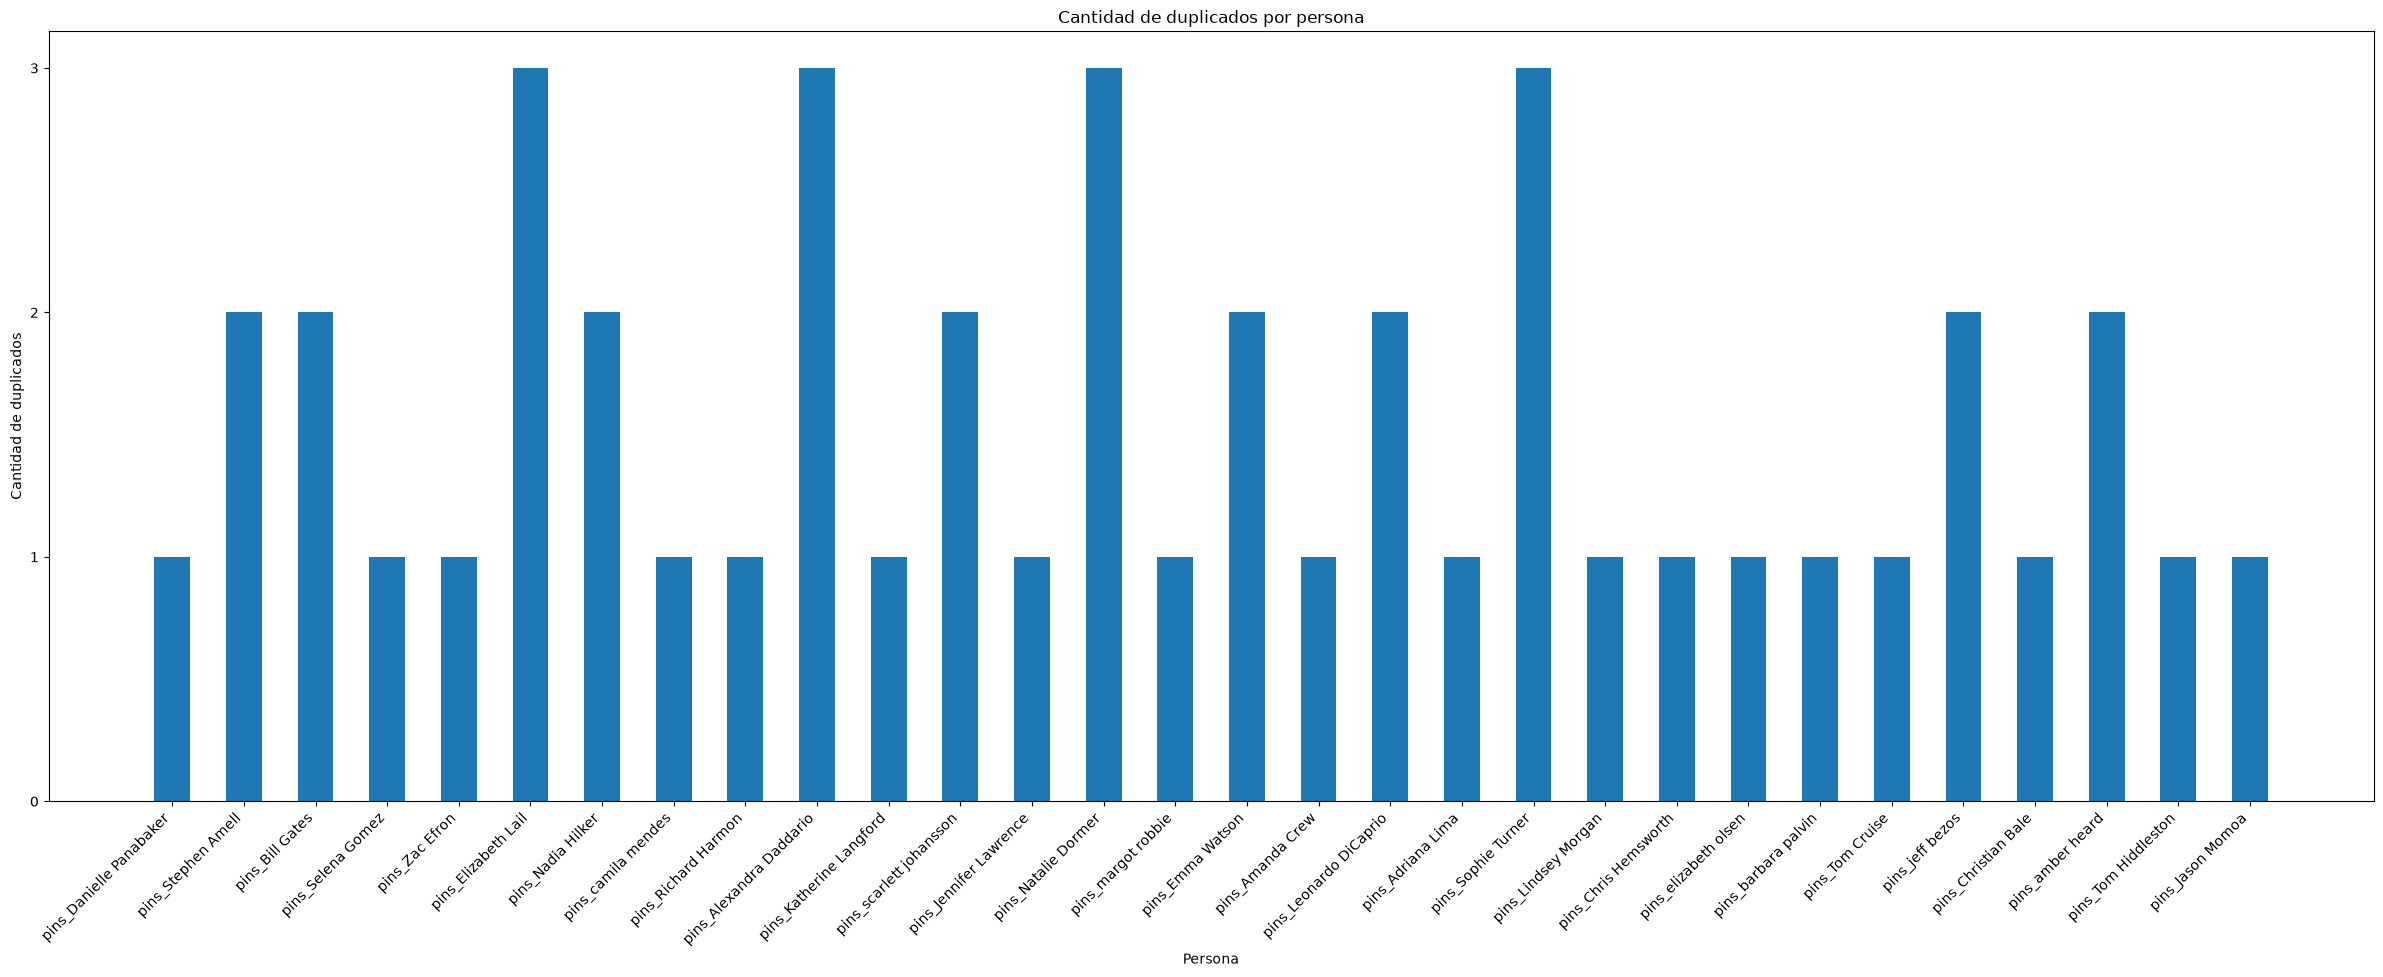

In [54]:
grafico_barra(
    list(cantidad_duplicados_por_persona.keys()),
    list(cantidad_duplicados_por_persona.values()),
    "Cantidad de duplicados por persona",
    "Persona",
    "Cantidad de duplicados",
    1
)

Hay al menos 46 imagenes duplicadas, distribuidas entre 30 famosos distintos.

In [51]:
# Imágenes que se deben conservar: únicamente las imagen_1
imagenes_conservar = {}

for resultado in resultados_ordenados:
    persona = resultado["persona"]

    if persona not in imagenes_conservar:
        imagenes_conservar[persona] = set()

    imagenes_conservar[persona].add(resultado["imagen_1"])

# Crear una nueva versión sin las imágenes duplicadas (imagen_2)
personas_cumplen_ruta_sin_duplicados = {}

for persona, rutas in personas_cumplen_ruta.items():
    imagenes_a_conservar = imagenes_conservar.get(persona, set())

    imagenes_a_eliminar = {
        resultado["imagen_2"]
        for resultado in resultados_ordenados
        if resultado["persona"] == persona
        and resultado["imagen_2"] not in imagenes_a_conservar
    }

    personas_cumplen_ruta_sin_duplicados[persona] = [
        ruta for ruta in rutas
        if ruta not in imagenes_a_eliminar
    ]

personas_cumplen_ruta_sin_duplicados

{'pins_Adriana Lima': ['Adriana Lima0_0.jpg',
  'Adriana Lima101_3.jpg',
  'Adriana Lima102_4.jpg',
  'Adriana Lima103_5.jpg',
  'Adriana Lima105_7.jpg',
  'Adriana Lima106_8.jpg',
  'Adriana Lima107_9.jpg',
  'Adriana Lima108_10.jpg',
  'Adriana Lima109_11.jpg',
  'Adriana Lima10_2.jpg',
  'Adriana Lima110_13.jpg',
  'Adriana Lima111_14.jpg',
  'Adriana Lima112_15.jpg',
  'Adriana Lima113_16.jpg',
  'Adriana Lima114_17.jpg',
  'Adriana Lima115_18.jpg',
  'Adriana Lima116_19.jpg',
  'Adriana Lima118_20.jpg',
  'Adriana Lima11_12.jpg',
  'Adriana Lima120_22.jpg',
  'Adriana Lima121_23.jpg',
  'Adriana Lima122_24.jpg',
  'Adriana Lima123_25.jpg',
  'Adriana Lima124_26.jpg',
  'Adriana Lima125_27.jpg',
  'Adriana Lima126_28.jpg',
  'Adriana Lima127_29.jpg',
  'Adriana Lima128_30.jpg',
  'Adriana Lima129_31.jpg',
  'Adriana Lima12_21.jpg',
  'Adriana Lima130_33.jpg',
  'Adriana Lima131_34.jpg',
  'Adriana Lima132_35.jpg',
  'Adriana Lima134_36.jpg',
  'Adriana Lima136_37.jpg',
  'Adriana L